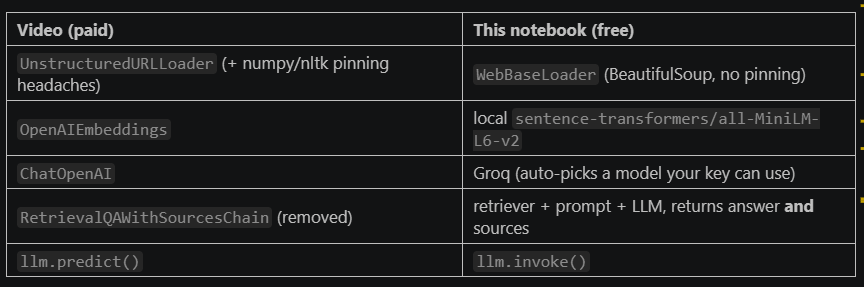

In [2]:
!pip install -q langchain-core langchain-community langchain-groq langchain-huggingface langchain-text-splitters faiss-cpu sentence-transformers beautifulsoup4 requests gradio

In [3]:
import os
from google.colab import userdata

os.environ["GROQ_API_KEY"] = userdata.get("GROQ_API_KEY")
print("Groq key loaded:", bool(os.environ["GROQ_API_KEY"]))

Groq key loaded: True


In [4]:
from groq import Groq
from langchain_groq import ChatGroq

client = Groq(api_key=os.environ["GROQ_API_KEY"])
available = sorted(m.id for m in client.models.list().data)
print("Available:", available)

prefer = ["llama-3.3-70b-versatile", "openai/gpt-oss-120b", "openai/gpt-oss-20b",
          "llama-3.1-8b-instant", "qwen/qwen3-32b"]
skip = ("whisper", "tts", "guard", "orpheus", "compound")
MODEL = next((m for m in prefer if m in available),
             next(m for m in available if not any(x in m for x in skip)))
print("Using:", MODEL)

def get_llm(temperature=0.2):
    return ChatGroq(model=MODEL, temperature=temperature, max_retries=6)

# sanity check BEFORE building anything (video step 10)
print(get_llm().invoke("In two sentences, what is Retrieval Augmented Generation?").content)

Available: ['allam-2-7b', 'canopylabs/orpheus-arabic-saudi', 'canopylabs/orpheus-v1-english', 'meta-llama/llama-prompt-guard-2-22m', 'meta-llama/llama-prompt-guard-2-86m', 'openai/gpt-oss-120b', 'openai/gpt-oss-20b', 'openai/gpt-oss-safeguard-20b', 'qwen/qwen3.8-27b', 'whisper-large-v3', 'whisper-large-v3-turbo']
Using: openai/gpt-oss-120b
Retrieval‑augmented generation (RAG) is a technique that combines a large language model with an external knowledge base: the model first retrieves relevant documents or passages from the source, then conditions its generation on that retrieved information. This allows the system to produce up‑to‑date, factual, and domain‑specific responses while keeping the fluency and reasoning abilities of the underlying generative model.


##Choose the website URLs

In [6]:
URLs = [
    "https://en.wikipedia.org/wiki/Large_language_model",
    "https://en.wikipedia.org/wiki/Retrieval-augmented_generation",
    "https://en.wikipedia.org/wiki/Transformer_(deep_learning_architecture)",
]

### (Optional) The `sitemap.xml` trick
Every site's `/sitemap.xml` lists its public URLs. This helper reads one and returns the first few links.
Skip this cell if you already have URLs. Some big sites block scrapers, so try a small/friendly site.

In [7]:
import re, requests

HEADERS = {"User-Agent": "WebsiteChatbotStudyProject/1.0 (personal learning project)"}

def urls_from_sitemap(sitemap_url, limit=10):
    r = requests.get(sitemap_url, headers=HEADERS, timeout=20)
    locs = re.findall(r"<loc>\s*(.*?)\s*</loc>", r.text)
    if locs and all(u.endswith(".xml") for u in locs):      # sitemap index -> follow the first one
        r = requests.get(locs[0], headers=HEADERS, timeout=20)
        locs = re.findall(r"<loc>\s*(.*?)\s*</loc>", r.text)
    return locs[:limit]

# Example (uncomment and replace with a site you are allowed to scrape):
# URLs = urls_from_sitemap("https://example.com/sitemap.xml", limit=8)
print(URLs)

['https://en.wikipedia.org/wiki/Large_language_model', 'https://en.wikipedia.org/wiki/Retrieval-augmented_generation', 'https://en.wikipedia.org/wiki/Transformer_(deep_learning_architecture)']


## Scrape into Documents (one per URL)

In [8]:
from langchain_community.document_loaders import WebBaseLoader

data, failed = [], []
for url in URLs:
    try:
        loaded = WebBaseLoader(web_paths=[url], header_template=HEADERS).load()
        data += [d for d in loaded if d.page_content.strip()]
    except Exception as e:
        failed.append((url, str(e)[:100]))

print("Pages loaded:", len(data))
print("Failed:", failed)
print(data[0].metadata)            # {'source': 'https://...'}  <- this powers "sources" later
print(len(data[0].page_content), "characters in page 1")

/tmp/ipykernel_446/3167975671.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import WebBaseLoader


Pages loaded: 3
Failed: []
{'source': 'https://en.wikipedia.org/wiki/Large_language_model', 'title': 'Large language model - Wikipedia', 'language': 'en'}
116603 characters in page 1


## Chunk
`chunk_size=1000`, `chunk_overlap=200` as in the video. We use `RecursiveCharacterTextSplitter`, which splits on paragraphs → lines → words, so it works even when a page has few newlines.
Every chunk keeps its page URL in `metadata["source"]`.

In [9]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

text_splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=200)
text_chunks = text_splitter.split_documents(data)

print("Chunks:", len(text_chunks))
print(text_chunks[0].metadata)
print(text_chunks[0].page_content[:300])

Chunks: 354
{'source': 'https://en.wikipedia.org/wiki/Large_language_model', 'title': 'Large language model - Wikipedia', 'language': 'en'}
Large language model - Wikipedia































Jump to content







Main menu





Main menu
move to sidebar
hide



		Navigation
	


Main pageContentsCurrent eventsRandom articleAbout WikipediaContact us





		Contribute
	


HelpLearn to editCommunity portalRecent changesUpload 


##Embeddings (sanity check first, then the knowledge base)

In [10]:
from langchain_huggingface import HuggingFaceEmbeddings

embeddings = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2")

query_result = embeddings.embed_query("Hello world")
print(len(query_result))        # 384 = dimension of this model (OpenAI ada-002 was 1536)
print(query_result[:5])

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

384
[-0.03447728976607323, 0.03102319873869419, 0.0067349751479923725, 0.026109017431735992, -0.03936200216412544]


In [11]:
from langchain_community.vectorstores import FAISS

vectorstore = FAISS.from_documents(text_chunks, embeddings)

# which chunk is closest in meaning to a question?
hit = vectorstore.similarity_search("What is a transformer?", k=1)[0]
print(hit.metadata["source"])
print(hit.page_content[:300])

https://en.wikipedia.org/wiki/Transformer_(deep_learning_architecture)
All transformers have the same primary components:
Tokenizers, which convert text into tokens.
Embedding layer, which converts tokens and positions of the tokens into vector representations.
Transformer layers, which carry out repeated transformations on the vector representations, extracting more a


##The RAG chain with sources
Each question: retrieve top-4 chunks → LLM answers **only** from them → we also return which URLs the chunks came from.
If the answer is the refusal sentence, no sources are shown.

In [12]:
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser

NOT_RELEVANT = "I can only answer questions about the provided websites."

rag_prompt = ChatPromptTemplate.from_template("""
You are a helpful assistant for a specific set of websites.
Answer using ONLY the context below.
If the context does not contain the answer, reply exactly: {not_relevant}

Context:
{context}

Question: {question}

Answer:
""")

retriever = vectorstore.as_retriever(search_kwargs={"k": 4})       # top-k = 4 like the video
rag_chain = rag_prompt | get_llm(0.2) | StrOutputParser()

def ask(question):
    docs = retriever.invoke(question)
    context = "\n\n".join(f"[{d.metadata.get('source', '')}]\n{d.page_content}" for d in docs)
    answer = rag_chain.invoke({"context": context, "question": question, "not_relevant": NOT_RELEVANT})
    sources = [] if NOT_RELEVANT in answer else sorted({d.metadata.get("source", "") for d in docs})
    return {"answer": answer, "sources": sources}

## Test it (in-domain, then prove it is closed-domain)

In [13]:
import textwrap

result = ask("What is retrieval-augmented generation?")
print(textwrap.fill(result["answer"], width=120))
print("\nSources:", result["sources"])

Retrieval‑augmented generation (RAG) is an approach that combines a large language model (LLM) with an external
document‑retrieval system. When a query is received, a retriever searches a vector‑based store (or other index) to fetch
the most relevant documents. Those retrieved passages are then incorporated—typically via prompt engineering—into the
LLM’s input so that the model can generate its answer using both its internal knowledge and the external, up‑to‑date
information. In other words, RAG augments a parametric language model with a non‑parametric memory accessed at inference
time, allowing the generated output to be grounded in retrieved documents.

Sources: ['https://en.wikipedia.org/wiki/Large_language_model', 'https://en.wikipedia.org/wiki/Retrieval-augmented_generation']


In [14]:
# Closed-domain test: this should be REFUSED (the failure is the feature)
result = ask("Tell me about India")
print(result["answer"])
print("Sources:", result["sources"])

I can only answer questions about the provided websites.
Sources: []


##Interactive chat loop

In [15]:
while True:
    query = input("Prompt: ").strip()
    if query == "exit":
        print("Exiting")
        break
    if query == "":
        continue
    res = ask(query)
    print("Answer:", res["answer"])
    if res["sources"]:
        print("Sources:", ", ".join(res["sources"]))

Prompt: explain
Answer: Large language models (LLMs) are deep‑learning systems that process and generate text by learning statistical patterns from massive corpora.  According to the provided context, they exhibit **reasoning and deep insights**, such that an LLM can, for example, predict the name of a criminal in a detective novel after processing the entire story up to the revelation.  Some observers describe this capability as “alien intelligence,” likening untuned LLMs to inscrutable “Shoggoths” whose inner workings are hidden beneath a “smiling façade” created by reinforcement‑learning‑from‑human‑feedback (RLHF) tuning.

The performance of LLMs often appears as a **step‑function** or “emergence,” where sudden jumps in ability are observed as model size or data scale increases.  Because LLMs are typically treated as **black boxes**, it is not clear how they accomplish linguistic tasks or whether they model aspects of the human brain or mind.

To address this opacity, the subfield o

#a web chat interface using Gradio

In [16]:
import gradio as gr

def chat_fn(message, history):
    res = ask(message)
    text = res["answer"]
    if res["sources"]:
        text += "\n\nSources:\n" + "\n".join(f"- {s}" for s in res["sources"])
    return text

demo = gr.ChatInterface(fn=chat_fn, title="Website Chatbot",
                        description="Ask about the pages you indexed. Off-topic questions are refused.")
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://67fe4f11fb34fd0e17.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
